# Predicting `Gene –reduce→ Disease` links in the HALD knowledge graph with weighted metapaths (networkx version)

**Goal.** HALD is a knowledge graph of genes, diseases and other biomedical entities. We want to predict which genes **reduce** which diseases using only the *structure* of the graph. The method is the **degree-weighted path count (DWPC)** of Himmelstein & Baranzini (2015) and Himmelstein et al. (2017, Project Rephetio).

**Tools.** networkx holds the graph in memory and answers questions about it (rdflib is used once, to read the RDF file). NumPy, SciPy and scikit-learn do the counting and the modelling. The notebook has the same sections and the same method as the SPARQL and Neo4j versions; only the way we store and query the graph differs (here there is no database to install), and from Section 4 onwards the two notebooks are identical. Nothing is written to disk.

## Plan of the notebook

| Section | What we do |
|---|---|
| 1 | Read HALD into a networkx graph and look at its node classes |
| 2 | Extract the target relation and the typed edges (metaedges) |
| 3 | Node degrees |
| 4 | Metapaths |
| 5 | The degree-weighted path count (DWPC) |
| 6 | Positive and negative examples |
| 7 | Choosing the damping exponent $w$ |
| 8 | Model features |
| 9 | Permuted networks (null model) |
| 10 | Logistic regression and cross-validation |
| 11 | ROC analysis and interpretation |

## Section 1: Read HALD into a networkx graph and look at its node classes

### What HALD looks like
HALD is stored as an **RDF/XML** file. RDF describes a graph as *triples*: `subject predicate object`. For example `INS associated Diabetes` says that the gene `INS` is linked to the disease `Diabetes` by the predicate `associated`. Every node (an *individual*) also has a **class** (its node type), such as Gene or Disease; that is itself a triple, `INS rdf:type Gene`.

### networkx in a nutshell
**networkx** is a Python package for graphs held in memory. A `DiGraph` is a *directed* graph: it stores nodes (each can carry attributes, such as a class) and directed edges. The ones we use are:

* `graph.add_node(name, node_class=...)` and `graph.add_edge(source, target)`;
* `graph.successors(node)` and `graph.predecessors(node)`: the nodes at the other end of the edges leaving or entering `node`;
* `graph.nodes[node]["node_class"]`: the attribute stored on a node;
* `graph.edges`: all the edges.

No server and no query language are needed: the graph is an ordinary Python object, and questions are answered with Python loops.

### Reading the RDF file
We read the file with the Python package **rdflib**, which hands us all the triples. The function `read_hald_rdf` sorts them into two simple dictionaries:

* `node_class`: the class of every node, found from the triples `node rdf:type class`;
* `predicates_of_edge`: for every pair `(source, target)` of nodes, the set of predicates that link them. (Only predicates that really relate two HALD nodes are kept, and a node linked to itself is dropped.)

Using a *set* of predicates means that two predicates between the same pair of nodes end up under one key. This is how the predicates will be collapsed. The function takes the file name and the namespace as arguments, and returns its result.

In [1]:
import networkx as nx
import pandas as pd
from rdflib import Graph, RDF, OWL

HALD_RDF_FILE = "./HALD_Dataset/HALD.rdf"                              # path to the HALD RDF/XML file
HALD_NAMESPACE = "http://www.dummy.info/new.owl#"         # the web address that prefixes every HALD name

def read_hald_rdf(rdf_file, namespace):
    # Returns node_class (node name -> class name) and predicates_of_edge ((source, target) -> set of predicates).
    rdf_graph = Graph()
    rdf_graph.parse(rdf_file, format="xml")
    is_hald_name = lambda uri: str(uri).startswith(namespace)
    short_name = lambda uri: str(uri)[len(namespace):]

    node_class = {}
    for class_uri in rdf_graph.subjects(RDF.type, OWL.Class):
        if is_hald_name(class_uri):
            for node_uri in rdf_graph.subjects(RDF.type, class_uri):
                node_class.setdefault(short_name(node_uri), short_name(class_uri))

    relationship_uris = {uri for uri in rdf_graph.subjects(RDF.type, OWL.ObjectProperty) if is_hald_name(uri)}
    predicates_of_edge = {}
    for source_uri, predicate_uri, target_uri in rdf_graph:
        if predicate_uri in relationship_uris and source_uri != target_uri:
            source, target = short_name(source_uri), short_name(target_uri)
            if source in node_class and target in node_class:
                predicates_of_edge.setdefault((source, target), set()).add(short_name(predicate_uri))
    return node_class, predicates_of_edge

### Reading the file
We call the function once. It returns `node_class`, which maps each node to its class, and `predicates_of_edge`, which maps each pair of nodes to the set of predicates joining them.

In [2]:
node_class, predicates_of_edge = read_hald_rdf(HALD_RDF_FILE, HALD_NAMESPACE)
print(len(node_class), "nodes,", len(predicates_of_edge), "node pairs joined by at least one predicate")

12256 nodes, 59692 node pairs joined by at least one predicate


### How many nodes does each class have?
`pd.Series(node_class)` turns the dictionary into a column of class names indexed by node name, and `value_counts()` counts how many nodes each class has.

In [3]:
class_sizes = pd.Series(node_class).value_counts().to_dict()
pd.Series(class_sizes, name="number of nodes").to_frame()

,number of nodes
Gene,5624
Disease,3501
Mutation,2216
RNA,388
Carbohydrate,211
Lipid,177
Peptide,82
Protein,29
Pharmaceutical_Preparations,15
Toxin,13


### Listing the nodes of every class
Later we will refer to nodes by name, so we collect, for each class, the sorted list of its members.

In [4]:
nodes_by_class = dict()
for name, class_name in node_class.items():
    nodes_by_class.setdefault(class_name, []).append(name)
nodes_by_class = {class_name: sorted(names) for class_name, names in nodes_by_class.items()}

total_nodes = sum(len(names) for names in nodes_by_class.values())
print(f"{len(nodes_by_class)} classes, {total_nodes:,} nodes  (the full HALD file has 10 classes and 12,256 nodes)")
print("first genes:", nodes_by_class["Gene"][:5])
print("first diseases:", nodes_by_class["Disease"][:5])

10 classes, 12,256 nodes  (the full HALD file has 10 classes and 12,256 nodes)
first genes: ['A1BG', 'A2M', 'A2ML1', 'AAK1', 'ABAT']
first diseases: ['ACTH_Secreting_Pituitary_Adenoma', 'AIDS_Arteritis_Central_Nervous_System', 'AIDS_Associated_Nephropathy', 'AIDS_Dementia_Complex', 'AIDS_Related_Complex']


### What we have so far
* `node_class` and `predicates_of_edge`: the contents of the RDF file as two dictionaries.
* `class_sizes`: number of nodes per class.
* `nodes_by_class`: the names of the nodes in each class.

Genes (5,624) and diseases (3,501) dominate. **In Section 2** we will find the relation we want to predict, `Gene –reduce→ Disease`, and build the network from the typed edges.

## Section 2: The target relation and the typed edges

### The relation we want to predict
We want to predict **`Gene –reduce→ Disease`**: pairs where a gene reduces a disease. The known pairs are our **positive examples**,

$$\mathcal P=\{(g,d)\;:\;g\in\text{Gene},\ d\in\text{Disease},\ g\xrightarrow{\text{reduce}}d\}.$$

They are the node pairs in `predicates_of_edge` that go from a gene to a disease and whose set of predicates contains `reduce`.

In [5]:
target_pairs = sorted((source, target) for (source, target), predicates in predicates_of_edge.items()
                      if node_class[source] == "Gene" and node_class[target] == "Disease" and "reduce" in predicates)

print(len(target_pairs), "known Gene-reduce-Disease pairs")
print("examples:", target_pairs[:3])

132 known Gene-reduce-Disease pairs
examples: [('ABCC3', 'Pancreatic_Neoplasms'), ('ACE', 'Anemia_Sickle_Cell'), ('ACE', 'Cardiovascular_Diseases')]


### Metaedges: the typed edges of the network
To use the *structure* of the graph we need all its edges, grouped by the types of the nodes they join. A **metaedge** is an ordered pair of node classes $(a,b)$, and it contains every edge $x\to y$ where $x$ is of class $a$ and $y$ is of class $b$. For example the metaedge $(\text{Gene},\text{Disease})$ holds all the edges from a gene to a disease.

HALD has about 3,000 different predicates, far too many to treat separately. We therefore make two simplifications:

* **Collapse the predicates.** An edge $x\to y$ exists if *any* predicate joins $x$ to $y$. If two predicates join the same pair, that is still one edge (`predicates_of_edge` already holds one set per pair).
* **Drop self-loops**, edges from a node to itself (`read_hald_rdf` already did this).

### Hiding the answer: avoiding leakage
There is one more important rule. If the `reduce` edges stayed in the network, a model could "predict" a gene–disease pair simply by finding the very edge we want it to predict. This is called **leakage**, and to avoid it we **remove the `reduce` predicate between genes and diseases** from the network before anything else is computed. Note that we remove the *predicate* (i.e. the edge), not the *pair* (the nodes). If the same gene and disease are also linked by another predicate (such as `associated`), that edge stays, since it is genuine evidence for the potential existence of a link that would be available at prediction time.

### Building the network
We create a `DiGraph`, add every node with its class as an attribute, and then add each edge. For a gene–disease pair we first take `reduce` out of its set of predicates, and we add the edge only if some predicate is left.

In [6]:
hald_network = nx.DiGraph()
for name, class_name in node_class.items():
    hald_network.add_node(name, node_class=class_name)

for (source, target), predicates in predicates_of_edge.items():
    if node_class[source] == "Gene" and node_class[target] == "Disease":
        predicates = predicates - {"reduce"}
    if predicates:                                       # some predicate remains, so the edge stays
        hald_network.add_edge(source, target, predicates=predicates)

print(hald_network.number_of_nodes(), "nodes,", hald_network.number_of_edges(), "edges")

12256 nodes, 59638 edges


### Grouping the edges by metaedge
We now sort the edges into a dictionary. Its keys are the metaedges, written as `(source class, target class)`, and each value is the list of `(source node, target node)` edges in that metaedge.

In [7]:
edges_by_metaedge = dict()
for source, target in hald_network.edges:
    metaedge = (node_class[source], node_class[target])
    # if the dictionary entry does not exist, create an empty list, then append to it.
    edges_by_metaedge.setdefault(metaedge, []).append((source, target))

# sort everything, so that the results do not depend on the order in which the edges happened to be read
edges_by_metaedge = {metaedge: sorted(edges) for metaedge, edges in sorted(edges_by_metaedge.items())}

number_of_edges = sum(len(edges) for edges in edges_by_metaedge.values())
print(f"{len(edges_by_metaedge)} metaedges, {number_of_edges:,} distinct edges  (the full HALD file has 63 metaedges and 59,638 edges)")

metaedge_sizes = pd.DataFrame(
    [(source_class, target_class, len(edges)) for (source_class, target_class), edges in edges_by_metaedge.items()],
    columns=["source class", "target class", "number of edges"]).sort_values("number of edges", ascending=False)
metaedge_sizes.head(10)

63 metaedges, 59,638 distinct edges  (the full HALD file has 63 metaedges and 59,638 edges)


,source class,target class,number of edges
9,Disease,Disease,36724
19,Gene,Disease,7498
10,Disease,Gene,4559
20,Gene,Gene,3266
28,Lipid,Disease,963
1,Carbohydrate,Disease,894
11,Disease,Lipid,695
8,Disease,Carbohydrate,681
35,Mutation,Disease,570
12,Disease,Mutation,424


### Checking the effect of hiding the target
How much did removing `reduce` change the Gene→Disease metaedge? Each of the target pairs is either still joined by some other predicate, or it has disappeared from the network completely.

In [8]:
gene_disease_edges = set(edges_by_metaedge[("Gene", "Disease")])
still_linked = [pair for pair in target_pairs if pair in gene_disease_edges]

print(f"Gene->Disease edges after removing 'reduce': {len(gene_disease_edges):,}")
print(f"target pairs still linked by another predicate: {len(still_linked)} of {len(target_pairs)}")
print(f"target pairs that vanished from the network:    {len(target_pairs) - len(still_linked)}")

Gene->Disease edges after removing 'reduce': 7,498
target pairs still linked by another predicate: 78 of 132
target pairs that vanished from the network:    54


### What we have so far
* `hald_network`: the network as a networkx `DiGraph` (the target relation is hidden in it).
* `target_pairs`: the 132 positive examples.
* `edges_by_metaedge`: the same edges, as 63 lists, one per metaedge.

**In Section 3** we will count how many neighbours each node has within each metaedge (its *degree*), which is what lets us down-weight paths that pass through very well-connected "hub" nodes.

## Section 3: Node degrees

### Why degrees matter
Some nodes are *hubs*: they are linked to a huge number of other nodes. A path that runs through a hub says little, because a hub is connected to almost everything. In the next sections we will give each path a weight that shrinks as the degrees of the nodes along it grow, so we first need to know every node's degree.

### Degree within a metaedge
A node's degree is the number of neighbours it has. Because the network is typed, we count neighbours **within one metaedge at a time**. For an edge $u\to v$ in the metaedge $(a,b)$, we use

$$d^{\text{out}}_{ab}(u)=\#\{v:\ u\to v \text{ is an edge of }(a,b)\},\qquad d^{\text{in}}_{ab}(v)=\#\{u:\ u\to v \text{ is an edge of }(a,b)\}.$$

The *out-degree* of $u$ counts the edges that leave $u$ in this metaedge, and the *in-degree* of $v$ counts the edges that arrive at $v$. The same gene therefore has a different degree in $(\text{Gene},\text{Disease})$ than in $(\text{Gene},\text{Gene})$, and this is intended: the weight of a Gene→Disease step should reflect how many diseases the gene is linked to, not how many other things it touches.

### Counting
For each metaedge we have the list of its edges, so the out-degree of a node is the number of times it appears as a *source*, and the in-degree is the number of times it appears as a *target*. Python's `Counter` does exactly this counting. A `Counter` also returns 0 for a node it has never seen, which is the right answer for a node with no edges in a metaedge.

In [9]:
from collections import Counter

out_degree = {}     # out_degree[metaedge][node] = number of edges leaving the node in that metaedge
in_degree = {}      # in_degree[metaedge][node]  = number of edges arriving at the node in that metaedge

for metaedge, edges in edges_by_metaedge.items():
    out_degree[metaedge] = Counter(source for source, target in edges)
    in_degree[metaedge] = Counter(target for source, target in edges)

print("example: out-degree of INS in (Gene, Disease):", out_degree[("Gene", "Disease")]["INS"])
print("example: in-degree of Diabetes_Mellitus in (Gene, Disease):", in_degree[("Gene", "Disease")]["Diabetes_Mellitus"])
print("a gene with no edges in the metaedge gets 0:", out_degree[("Gene", "Disease")]["A1BG"])

example: out-degree of INS in (Gene, Disease): 168
example: in-degree of Diabetes_Mellitus in (Gene, Disease): 135
a gene with no edges in the metaedge gets 0: 0


### Checking the counts with networkx
To make sure the counting is right, we ask networkx for the same number in a different way. We take the gene with the largest out-degree in $(\text{Gene},\text{Disease})$ and count its successors in the network that are diseases. The two numbers must be equal.

Note that networkx's own `hald_network.out_degree(gene)` is **not** the number we need: it counts the neighbours of *all* classes, whereas our degree is specific to one metaedge. The last line shows the difference.

In [10]:
gene_disease = ("Gene", "Disease")
best_connected_gene = out_degree[gene_disease].most_common(1)[0][0]      # the gene with the largest out-degree

degree_from_networkx = sum(1 for neighbour in hald_network.successors(best_connected_gene) if node_class[neighbour] == "Disease")

assert degree_from_networkx == out_degree[gene_disease][best_connected_gene], "degree mismatch"
print(f"check passed: {best_connected_gene} has {degree_from_networkx} diseases (networkx) = {out_degree[gene_disease][best_connected_gene]} (our count)")
print(f"networkx's own out_degree counts neighbours of every class: {hald_network.out_degree(best_connected_gene)}")

check passed: INS has 168 diseases (networkx) = 168 (our count)
networkx's own out_degree counts neighbours of every class: 260


### One gene, many degrees
The best-connected gene has a different degree in every metaedge it takes part in. The table lists its out-degree in each metaedge where it is the source.

In [11]:
degrees_of_best_gene = pd.Series(
    {f"{source_class} -> {target_class}": out_degree[(source_class, target_class)][best_connected_gene]
     for (source_class, target_class) in edges_by_metaedge if source_class == "Gene"},
    name=f"out-degree of {best_connected_gene}")
degrees_of_best_gene[degrees_of_best_gene > 0].sort_values(ascending=False).to_frame()

,out-degree of INS
Gene -> Disease,168
Gene -> Gene,65
Gene -> Peptide,8
Gene -> Carbohydrate,7
Gene -> Lipid,6
Gene -> Mutation,5
Gene -> RNA,1


### How uneven are the degrees?
Finally, look at the out-degree of the genes in $(\text{Gene},\text{Disease})$. If degrees were similar for all genes, weighting by degree would change little. They are not.

In [12]:
gene_out_degrees = pd.Series({gene: out_degree[gene_disease][gene] for gene in nodes_by_class["Gene"]})
linked_genes = gene_out_degrees[gene_out_degrees > 0]

print(f"{len(linked_genes):,} of {len(gene_out_degrees):,} genes have at least one Gene->Disease edge")
print(f"median out-degree {linked_genes.median():.0f}, mean {linked_genes.mean():.1f}, maximum {linked_genes.max()}")

2,054 of 5,624 genes have at least one Gene->Disease edge
median out-degree 2, mean 3.7, maximum 168


### What we have so far
* `out_degree[metaedge][node]` and `in_degree[metaedge][node]`: the metaedge-specific degrees of every node, checked against networkx.

The degrees are very uneven: the median gene has only a handful of diseases, while a few hubs have over a hundred. **In Section 4** we will define *metapaths*, the typed routes between a gene and a disease, and list all the ones we will use.

## Section 4: Metapaths

### Typed routes between a gene and a disease
To predict whether a gene is linked to a disease, we look at the *routes* that already connect them in the network. Because the network is typed, a route is described by the **types** of the nodes it visits. Such a type pattern is a **metapath**: a sequence of node classes joined by metaedges,

$$m = \big(a_0 \xrightarrow{e_1} a_1 \xrightarrow{e_2} \cdots \xrightarrow{e_L} a_L\big),\qquad L=\text{length of the metapath}.$$

Every route in the graph that follows this pattern is an *instance* of the metapath. For our task each metapath starts at a Gene ($a_0=\text{Gene}$) and ends at a Disease ($a_L=\text{Disease}$).

### Walking along an edge in either direction
Metaedges have a direction, but a route may use an edge **backwards**. For instance a gene can reach a disease through another gene that is linked to the same disease, and that second step goes *against* the Gene→Disease arrow. We write a forward step as `>` and a backward step as `<`, followed by the class we arrive at. Some examples:

| Metapath | Meaning |
|---|---|
| `Gene>Disease` | the gene is linked directly to the disease (by a predicate other than `reduce`) |
| `Gene>Gene>Disease` | the gene is linked to another gene, which is linked to the disease |
| `Gene>Disease>Disease` | the gene is linked to a related disease, which is linked to the target disease |
| `Gene>Disease<Gene>Disease` | the gene shares a disease with another gene, which is linked to the target disease (length 3) |

### How long can a metapath be?
The number of possible metapaths grows very quickly with their length. From length 3 onwards a route can also revisit a node (for example `Gene>Disease<Gene>Disease` can return to the gene it started from), and such routes must be excluded when we count, which needs some extra care in Section 5. For length at most 2 this cannot happen, because self-loops were removed and a Gene is never a Disease.

We allow metapaths of **length up to 3**, which gives 516 of them. The limit is the setting `MAX_LENGTH`; the code that finds metapaths works for any value, but the number of metapaths (and the work to count their routes) explodes as it grows.

### Which steps are possible from each class?
First we list, for every class, the steps we can take from it. Each metaedge $(a,b)$ gives two steps: a **forward** step from $a$ to $b$ (written `>`) and a **backward** step from $b$ to $a$ (written `<`). A step is stored as `(direction, class we arrive at, metaedge it uses)`.

In [13]:
MAX_LENGTH = 3          # longest metapath we consider, counted in steps (edges)

steps_from_class = {}
for source_class, target_class in edges_by_metaedge:
    metaedge = (source_class, target_class)
    steps_from_class.setdefault(source_class, []).append((">", target_class, metaedge))    # forward step
    steps_from_class.setdefault(target_class, []).append(("<", source_class, metaedge))    # backward step

for direction, arrive_at, metaedge in steps_from_class["Gene"][:4]:
    print(f"from Gene, step '{direction}' to {arrive_at:12s} using metaedge {metaedge}")

from Gene, step '<' to Carbohydrate using metaedge ('Carbohydrate', 'Gene')
from Gene, step '<' to Disease      using metaedge ('Disease', 'Gene')
from Gene, step '>' to Carbohydrate using metaedge ('Gene', 'Carbohydrate')
from Gene, step '>' to Disease      using metaedge ('Gene', 'Disease')


### Finding all metapaths from Gene to Disease
We build metapaths one step at a time, starting at Gene. At each point we ask two questions:

1. *Are we at a Disease, having taken at least one step?* Then the steps so far form a metapath, and we record it.
2. *Have we reached the maximum length?* If not, we try every possible next step from the current class and continue from there.

A function that calls itself in this way is called **recursive**. Each metapath is stored under a readable name, such as `Gene>Gene>Disease`, together with its list of steps (we need the steps to compute the path counts in Section 5).

In [14]:
def find_metapaths(steps_from_class, max_length, start_class, end_class):
    # Returns a dictionary: metapath name -> list of steps; each step is (direction, class arrived at, metaedge used)
    found = {}

    def extend(steps_so_far, current_class):
        if steps_so_far and current_class == end_class:
            name = start_class + "".join(direction + arrive_at for direction, arrive_at, metaedge in steps_so_far)
            found[name] = steps_so_far
        if len(steps_so_far) == max_length:
            return
        for step in steps_from_class.get(current_class, []):
            direction, arrive_at, metaedge = step
            extend(steps_so_far + [step], arrive_at)

    extend([], start_class)
    return found

metapaths = find_metapaths(steps_from_class, MAX_LENGTH, "Gene", "Disease")
print(len(metapaths), f"metapaths from Gene to Disease with at most {MAX_LENGTH} steps")
for i in metapaths:
    print(i)

516 metapaths from Gene to Disease with at most 3 steps
Gene<Carbohydrate>Carbohydrate>Disease
Gene<Carbohydrate>Carbohydrate<Disease
Gene<Carbohydrate<Carbohydrate>Disease
Gene<Carbohydrate<Carbohydrate<Disease
Gene<Carbohydrate>Disease
Gene<Carbohydrate>Disease>Disease
Gene<Carbohydrate>Disease<Disease
Gene<Carbohydrate>Gene<Disease
Gene<Carbohydrate>Gene>Disease
Gene<Carbohydrate>Lipid<Disease
Gene<Carbohydrate>Lipid>Disease
Gene<Carbohydrate>Mutation<Disease
Gene<Carbohydrate>Mutation>Disease
Gene<Carbohydrate>Peptide<Disease
Gene<Carbohydrate>Peptide>Disease
Gene<Carbohydrate>Protein<Disease
Gene<Carbohydrate>Protein>Disease
Gene<Carbohydrate>RNA<Disease
Gene<Carbohydrate>RNA>Disease
Gene<Carbohydrate<Disease
Gene<Carbohydrate<Disease>Disease
Gene<Carbohydrate<Disease<Disease
Gene<Carbohydrate<Gene<Disease
Gene<Carbohydrate<Gene>Disease
Gene<Carbohydrate<Lipid<Disease
Gene<Carbohydrate<Lipid>Disease
Gene<Carbohydrate<Mutation<Disease
Gene<Carbohydrate<Mutation>Disease
Gene<Carbohy

### Looking at the result
How many metapaths are there of each length, and what do the length-1 metapaths look like?

In [15]:
metapath_lengths = pd.Series({name: len(steps) for name, steps in metapaths.items()})
print("number of metapaths by length:")
print(metapath_lengths.value_counts().sort_index().to_string())

print("\nlength 1:", [name for name in metapaths if metapath_lengths[name] == 1])
print("some of length 2:", [name for name in metapaths if metapath_lengths[name] == 2][:6])
print("some of length 3:", [name for name in metapaths if metapath_lengths[name] == 3][:4])
print("includes Gene>Disease<Gene>Disease:", "Gene>Disease<Gene>Disease" in metapaths)

number of metapaths by length:
1      2
2     34
3    480

length 1: ['Gene<Disease', 'Gene>Disease']
some of length 2: ['Gene<Carbohydrate>Disease', 'Gene<Carbohydrate<Disease', 'Gene<Disease>Disease', 'Gene<Disease<Disease', 'Gene>Carbohydrate>Disease', 'Gene>Carbohydrate<Disease']
some of length 3: ['Gene<Carbohydrate>Carbohydrate>Disease', 'Gene<Carbohydrate>Carbohydrate<Disease', 'Gene<Carbohydrate<Carbohydrate>Disease', 'Gene<Carbohydrate<Carbohydrate<Disease']
includes Gene>Disease<Gene>Disease: True


### Reading the two length-1 metapaths
`Gene>Disease` follows the Gene→Disease edges forwards: the gene points at the disease. `Gene<Disease` follows the **Disease→Gene** edges backwards: a disease points at the gene. HALD contains both kinds of edge, so both are useful evidence. Remember that the Gene→Disease edges here exclude `reduce`, so neither can contain the target.

### What we have so far
* `metapaths`: a dictionary of all 516 metapaths from Gene to Disease with at most three steps, each with its list of steps.

**In Section 5** we will count the instances of each metapath between a gene and a disease, weighting every path by the degrees of the nodes on it. This is the *degree-weighted path count* (DWPC), the heart of the method.

## Section 5: The degree-weighted path count (DWPC)

### From a route to a number
For a gene $s$ and a disease $t$, a metapath $m$ has a number of routes (instances) joining them. The simplest feature is the **path count**: how many routes there are. But a path count is dominated by hubs. A route that passes through a node with 400 neighbours tells us much less than a route through a node with 3 neighbours.

To account for this, we give each route a weight that shrinks as the degrees of its nodes grow. Each edge $u\to v$ on a route contributes the two degrees from Section 3: the out-degree of $u$ and the in-degree of $v$ in that edge's metaedge. For a route $\pi=(u_0,u_1,\dots,u_L)$ following the metaedges $e_1,\dots,e_L$, the **path-degree product** is

$$\mathrm{PDP}(\pi)=\prod_{i=1}^{L}\Big[d^{\text{out}}_{e_i}(u_{i-1})\Big]^{-w}\Big[d^{\text{in}}_{e_i}(u_i)\Big]^{-w},$$

and the **degree-weighted path count** adds up the weights of all routes from $s$ to $t$ that follow the metapath and **never visit a node twice**:

$$\boxed{\;\mathrm{DWPC}_m(s,t;w)=\sum_{\pi\ \text{from}\ s\ \text{to}\ t\ \text{following}\ m}\mathrm{PDP}(\pi)\;}$$

The **damping exponent** $w\ge 0$ sets how strongly hubs are punished. With $w=0$ every weight is 1, so the DWPC is the plain path count. The table shows the weight $d^{-w}$ that a node of degree $d$ contributes.

In [16]:
degrees_to_show = [1, 10, 100, 1000]
exponents_to_show = [0, 0.25, 0.5, 1.0]
pd.DataFrame({f"w = {w}": [round(d ** -w, 3) for d in degrees_to_show] for w in exponents_to_show},
             index=[f"degree {d}" for d in degrees_to_show])

,w = 0,w = 0.25,w = 0.5,w = 1.0
degree 1,1,1.000,1.000,1.000
degree 10,1,0.562,0.316,0.100
degree 100,1,0.316,0.100,0.010
degree 1000,1,0.178,0.032,0.001


### Counting all pairs at once with matrices
There are thousands of genes and diseases, so we need to count routes for *every* gene–disease pair quickly. The trick is to store each metaedge as a **matrix** and let matrix multiplication do the counting.

**Adjacency matrices.** For a metaedge $(a,b)$ the matrix $A_{ab}$ has one row per node of class $a$, one column per node of class $b$, and a 1 where an edge exists:

$$(A_{ab})_{xy}=1 \iff x\to y \text{ is an edge of metaedge } (a,b).$$

Most entries are 0, so we store them as *sparse* matrices (SciPy's `csr_matrix` keeps only the non-zero entries). First we give every node a row/column position within its class, then we fill in the matrices.

In [17]:
import numpy as np
import scipy.sparse as sp

node_position = {class_name: {node: position for position, node in enumerate(names)}
                 for class_name, names in nodes_by_class.items()}

adjacency_matrices = {}
for (source_class, target_class), edges in edges_by_metaedge.items():
    rows = [node_position[source_class][source] for source, target in edges]
    columns = [node_position[target_class][target] for source, target in edges]
    shape = (len(nodes_by_class[source_class]), len(nodes_by_class[target_class]))
    adjacency_matrices[(source_class, target_class)] = sp.csr_matrix((np.ones(len(edges)), (rows, columns)), shape=shape)

gene_disease_matrix = adjacency_matrices[("Gene", "Disease")]
print("the (Gene, Disease) matrix has shape", gene_disease_matrix.shape, "and", gene_disease_matrix.nnz, "edges")

the (Gene, Disease) matrix has shape (5624, 3501) and 7498 edges


### Putting the weights into the matrix
Every edge of a route contributes the factor $\big[d^{\text{out}}(u)\big]^{-w}\big[d^{\text{in}}(v)\big]^{-w}$. We can build that factor **into** the matrix: multiply each row $u$ by $d^{\text{out}}(u)^{-w}$ and each column $v$ by $d^{\text{in}}(v)^{-w}$. The result is the **weighted adjacency matrix**

$$W_{ab}=D^{\text{out}}\,A_{ab}\,D^{\text{in}},\qquad D^{\text{out}}=\operatorname{diag}\!\big(d^{\text{out}}_{ab}(u)^{-w}\big),\quad D^{\text{in}}=\operatorname{diag}\!\big(d^{\text{in}}_{ab}(v)^{-w}\big),$$

so that $(W_{ab})_{uv}=d^{\text{out}}(u)^{-w}\,d^{\text{in}}(v)^{-w}$ if $u\to v$ is an edge, and 0 otherwise. We use the degrees `out_degree` and `in_degree` from Section 3. A node with no edges has degree 0, but its row (or column) is empty anyway, so we replace 0 by 1 to avoid dividing by zero.

In [18]:
def weighted_adjacency_matrices(w, adjacency_matrices, out_degree, in_degree, nodes_by_class):
    # the weighted matrix W of every metaedge, for damping exponent w
    weighted = {}
    for metaedge, adjacency in adjacency_matrices.items():
        source_class, target_class = metaedge
        out_degrees = np.array([out_degree[metaedge][node] for node in nodes_by_class[source_class]], dtype=float)
        in_degrees = np.array([in_degree[metaedge][node] for node in nodes_by_class[target_class]], dtype=float)
        out_weights = np.where(out_degrees > 0, out_degrees, 1.0) ** -w      # d_out ^ -w  (0 replaced by 1)
        in_weights = np.where(in_degrees > 0, in_degrees, 1.0) ** -w         # d_in  ^ -w
        weighted[metaedge] = (sp.diags(out_weights) @ adjacency @ sp.diags(in_weights)).tocsr()
    return weighted

example_w = 0.4          # the value found best by the original papers; we choose our own w in Section 7
weighted_matrices = weighted_adjacency_matrices(example_w, adjacency_matrices, out_degree, in_degree, nodes_by_class)

# one entry by hand: INS -> Diabetes_Mellitus
gene, disease = "INS", "Diabetes_Mellitus"
metaedge = ("Gene", "Disease")
by_hand = (out_degree[metaedge][gene] * in_degree[metaedge][disease]) ** -example_w
from_matrix = weighted_matrices[metaedge][node_position["Gene"][gene], node_position["Disease"][disease]]
print(f"weight of the edge {gene} -> {disease}: by hand {by_hand:.5f}, from the matrix {from_matrix:.5f}")

weight of the edge INS -> Diabetes_Mellitus: by hand 0.01810, from the matrix 0.01810


### Chaining the steps of a metapath
Multiplying two weighted matrices adds up, over all middle nodes, the product of the weights of the two steps. That is exactly "sum over all routes of the product of the edge weights". So for a metapath with steps $e_1,\dots,e_L$ we multiply the step matrices together:

$$\mathrm{DWPC}^{\text{walks}}_m = M_1M_2\cdots M_L,\qquad M_i=\begin{cases}W_{e_i} & \text{forward step }(>)\\ W_{e_i}^{\top} & \text{backward step }(<)\end{cases}$$

A backward step uses the **transpose** because it follows the edge in the opposite direction. The entry in row $s$ and column $t$ of the result is the weighted route count from gene $s$ to disease $t$, for **all** genes and diseases at once.

The function below does the multiplication. We call the result "walks" for a reason explained next.

In [19]:
def step_matrices_of(steps, weighted_matrices):
    # the matrix of every step of the metapath (transposed for backward steps)
    matrices = []
    for direction, arrive_at, metaedge in steps:
        weighted = weighted_matrices[metaedge]
        matrices.append(weighted if direction == ">" else weighted.T.tocsr())
    return matrices

def walk_matrix(steps, weighted_matrices):
    matrices = step_matrices_of(steps, weighted_matrices)
    result = matrices[0]
    for matrix in matrices[1:]:
        result = result @ matrix
    return result

walks = walk_matrix(metapaths["Gene>Gene>Disease"], weighted_matrices)
print("Gene>Gene>Disease: matrix of shape", walks.shape, "with", walks.nnz, "gene-disease pairs joined by at least one route")

Gene>Gene>Disease: matrix of shape (5624, 3501) with 53260 gene-disease pairs joined by at least one route


### Routes must not visit a node twice
Matrix multiplication counts **walks**, which are allowed to come back to a node they have already visited. The DWPC counts only **paths**, which are not. Whether a walk can revisit a node depends on the length:

* **Length 1 and 2:** impossible. There are no self-loops, so a step never returns to the node it just left; and the first node is a Gene while the last is a Disease, so they can never be the same node.
* **Length 3**, nodes $(n_0,n_1,n_2,n_3)$: two repeats are possible, $n_0=n_2$ (the route goes back to its starting node) and $n_1=n_3$. A repeat of $n_0$ with $n_3$ is impossible because a Gene is not a Disease. A repeat can only happen if the two nodes have the same class, for example $n_0=n_2$ needs both to be Genes.

We remove the unwanted walks by subtraction. The walks with $n_0=n_2$ are counted by $\operatorname{diag}\!\big[(M_1\circ M_2^{\top})\mathbf 1\big]\,M_3$, where $\circ$ multiplies two matrices entry by entry and $\mathbf 1$ is a vector of ones (the diagonal holds, for each $n_0$, the weight of going out and straight back). Likewise the walks with $n_1=n_3$ are $M_1\operatorname{diag}\!\big[(M_2\circ M_3^{\top})\mathbf 1\big]$. A walk with *both* repeats has been subtracted twice, so we add it back, $M_1\circ M_2^{\top}\circ M_3$:

$$\mathrm{DWPC}_m = M_1M_2M_3 \;-\; \operatorname{diag}\!\big[(M_1\circ M_2^{\top})\mathbf 1\big]M_3 \;-\; M_1\operatorname{diag}\!\big[(M_2\circ M_3^{\top})\mathbf 1\big] \;+\; M_1\circ M_2^{\top}\circ M_3 .$$

Each correction applies only when the two nodes can be equal; the last term only for `Gene>Disease<Gene>Disease`-like metapaths where both can. This is the only place where length 3 needs more than length 2.


In [20]:
def dwpc_matrix(steps, weighted_matrices):
    # DWPC of every (gene, disease) pair for one metapath: rows = genes, columns = diseases
    assert len(steps) <= 3, "the matrix method is only corrected for metapaths of length up to 3"
    result = walk_matrix(steps, weighted_matrices)
    if len(steps) == 3:
        M1, M2, M3 = step_matrices_of(steps, weighted_matrices)
        classes = ["Gene"] + [arrive_at for direction, arrive_at, metaedge in steps]
        n0_can_equal_n2 = classes[0] == classes[2]
        n1_can_equal_n3 = classes[1] == classes[3]
        if n0_can_equal_n2:
            result = result - sp.diags(np.asarray(M1.multiply(M2.T).sum(axis=1)).ravel()) @ M3
        if n1_can_equal_n3:
            result = result - M1 @ sp.diags(np.asarray(M2.multiply(M3.T).sum(axis=1)).ravel())
        if n0_can_equal_n2 and n1_can_equal_n3:
            result = result + M1.multiply(M2.T).multiply(M3)
    return result.tocsr()

### An independent check: counting route by route

Beyond length 3 the number of corrections needed increases rapidly, and we need to include many new correction terms. For this reason we need an alternative to matrix-based calculations for longer paths.

In addition, matrix corrections are easy to get subtly wrong, so it is helpful to be able check them against a method that is obviously correct, if slow: **walk the graph one route at a time**. Starting at the gene, we follow every possible step of the metapath, skip any node already visited, multiply the weights $\big[d^{\text{out}}\,d^{\text{in}}\big]^{-w}$ along the way, and add up the weights of the routes that end at the disease.

This method needs no correction at all, and it works for **metapaths of any length**. This is how you would go beyond paths of length 3. The price is time: the number of routes explodes as paths get longer. First the neighbour lists, then the walker.

In [21]:
forward_neighbours = {}      # forward_neighbours[metaedge][node]  = nodes reached by a forward step (>)
backward_neighbours = {}     # backward_neighbours[metaedge][node] = nodes reached by a backward step (<)
for metaedge, edges in edges_by_metaedge.items():
    forward_neighbours[metaedge], backward_neighbours[metaedge] = {}, {}
    for source, target in edges:
        forward_neighbours[metaedge].setdefault(source, []).append(target)
        backward_neighbours[metaedge].setdefault(target, []).append(source)

def dwpc_by_walking(steps, gene, disease, w, forward_neighbours, backward_neighbours, out_degree, in_degree):
    # DWPC of one (gene, disease) pair, by following every route and adding up its weight
    total = 0.0

    def follow(step_number, current_node, weight, visited):
        nonlocal total
        if step_number == len(steps):                         # the metapath is complete
            if current_node == disease:
                total += weight
            return
        direction, arrive_at, metaedge = steps[step_number]
        if direction == ">":
            next_nodes = forward_neighbours[metaedge].get(current_node, [])
        else:
            next_nodes = backward_neighbours[metaedge].get(current_node, [])
        for next_node in next_nodes:
            if next_node in visited:                          # never visit a node twice
                continue
            if direction == ">":
                degrees = out_degree[metaedge][current_node] * in_degree[metaedge][next_node]
            else:
                degrees = in_degree[metaedge][current_node] * out_degree[metaedge][next_node]
            follow(step_number + 1, next_node, weight * degrees ** -w, visited | {next_node})

    follow(0, gene, 1.0, {gene})
    return total

### Comparing the two methods
We compare the matrix DWPC with the route-by-route DWPC for four gene–disease pairs (three known target pairs and one other pair), for $w=0$ (plain path counts) and $w=0.4$. We test **every** metapath of length 1 and 2, and a selection of length-3 metapaths that can revisit nodes, since those are the ones the correction is for. The largest difference must be tiny (rounding error only).

In [22]:
check_pairs = target_pairs[:3] + [(target_pairs[0][0], target_pairs[3][1])]
length_3_to_check = ["Gene>Disease<Gene>Disease", "Gene>Disease>Gene>Disease", "Gene>Gene>Gene>Disease",
                     "Gene>Gene<Gene>Disease", "Gene<Disease>Disease>Disease", "Gene>Disease<Disease>Disease"]
names_to_check = [name for name, steps in metapaths.items() if len(steps) <= 2] + [n for n in length_3_to_check if n in metapaths]

largest_difference, comparisons = 0.0, 0
for w in [0.0, 0.4]:
    matrices_at_w = weighted_adjacency_matrices(w, adjacency_matrices, out_degree, in_degree, nodes_by_class)
    for name in names_to_check:
        dwpc_all_pairs = dwpc_matrix(metapaths[name], matrices_at_w)
        for gene, disease in check_pairs:
            from_matrix = dwpc_all_pairs[node_position["Gene"][gene], node_position["Disease"][disease]]
            by_walking = dwpc_by_walking(metapaths[name], gene, disease, w,
                                         forward_neighbours, backward_neighbours, out_degree, in_degree)
            largest_difference = max(largest_difference, abs(from_matrix - by_walking))
            comparisons += 1

print(f"{comparisons} comparisons, largest difference {largest_difference:.1e}")
assert largest_difference < 1e-9, "the matrix DWPC and the route-by-route DWPC disagree"

336 comparisons, largest difference 9.7e-17


### Seeing the DWPC at work
For a well-connected target pair, the gene INS and the disease Diabetes_Mellitus, which metapaths connect the gene to the disease, and how much does the degree weighting change the picture? The table compares the plain path count ($w=0$) with the DWPC ($w=0.4$) for the metapaths of length 1 and 2.

In [23]:
gene, disease = "INS", "Diabetes_Mellitus"      # a well-connected target pair
row, column = node_position["Gene"][gene], node_position["Disease"][disease]
short_metapath_names = [name for name, steps in metapaths.items() if len(steps) <= 2]
matrices_w0 = weighted_adjacency_matrices(0.0, adjacency_matrices, out_degree, in_degree, nodes_by_class)
matrices_w04 = weighted_adjacency_matrices(0.4, adjacency_matrices, out_degree, in_degree, nodes_by_class)

comparison = pd.DataFrame({
    "path count (w=0)": [dwpc_matrix(metapaths[name], matrices_w0)[row, column] for name in short_metapath_names],
    "DWPC (w=0.4)": [dwpc_matrix(metapaths[name], matrices_w04)[row, column] for name in short_metapath_names],
}, index=short_metapath_names)

print(f"routes between the gene {gene} and the disease {disease}")
comparison[comparison["path count (w=0)"] > 0].sort_values("path count (w=0)", ascending=False).round(3)

routes between the gene INS and the disease Diabetes_Mellitus


,path count (w=0),DWPC (w=0.4)
Gene>Disease>Disease,132.0,0.166
Gene>Disease<Disease,130.0,0.138
Gene<Disease>Disease,128.0,0.174
Gene<Disease<Disease,128.0,0.156
Gene<Gene>Disease,43.0,0.220
Gene<Gene<Disease,28.0,0.167
Gene>Gene>Disease,28.0,0.146
Gene>Gene<Disease,20.0,0.123
Gene<Carbohydrate>Disease,7.0,0.167
Gene<Carbohydrate<Disease,6.0,0.275


### What we have so far
* `adjacency_matrices` and `weighted_adjacency_matrices(w, ...)`: every metaedge as a sparse matrix, with or without the degree weights.
* `dwpc_matrix(steps, weighted_matrices)`: the DWPC of **all** gene–disease pairs for a metapath of length up to 3, in one matrix.
* `dwpc_by_walking(steps, gene, disease, w)`: a slow but obviously correct route-by-route DWPC for one pair and any length, used to verify the matrices.

**In Section 6** we will build the data set for the model: the known target pairs as positive examples, and randomly chosen gene–disease pairs as negative examples.

## Section 6: Positive and negative examples

### What the model will learn from
We will train a classifier that looks at a (gene, disease) pair and says whether the gene reduces the disease. To learn, it needs examples of both answers:

* **Positive examples** are the pairs we know are true: the 132 pairs in `target_pairs`.
* **Negative examples** are pairs we treat as "not linked".

### Where do negatives come from?
HALD does not list pairs where a gene definitely does *not* reduce a disease. The absence of an edge only means "not recorded", and some missing pairs may well be true. The standard practical solution, also used by Himmelstein and colleagues, is to **sample negatives at random** from all gene–disease pairs that are not known positives. A few of them may be true links we simply do not know about, but with millions of possible pairs and only 132 known positives, almost all random pairs are genuinely unlinked.

There are $5624\times3501\approx19.7$ million possible gene–disease pairs, so we take a sample. We use **20,000** negatives, about 150 for every positive. The classes are very unbalanced (about 0.7% positives), which we will handle in the model by weighting the two classes. As the papers note, the quality of the prediction is limited by the small number of positives, not by the number of negatives.

### Sampling
The function below draws a random gene and a random disease, keeps the pair if it is not a positive, and repeats until it has the number we asked for. It uses a *seeded* random number generator, so every run produces the same sample. Everything the function needs is passed to it as an argument.

In [24]:
RANDOM_SEED = 42
NUMBER_OF_NEGATIVES = 20000

def sample_negative_pairs(genes, diseases, positive_pairs, number_wanted, random_generator):
    # Random (gene, disease) pairs that are not positive, with no pair chosen twice.
    positive_set = set(positive_pairs)
    negatives = set()
    while len(negatives) < number_wanted:
        gene = genes[random_generator.integers(len(genes))]
        disease = diseases[random_generator.integers(len(diseases))]
        if (gene, disease) not in positive_set:
            negatives.add((gene, disease))
    return sorted(negatives)

random_generator = np.random.default_rng(RANDOM_SEED)
negative_pairs = sample_negative_pairs(nodes_by_class["Gene"], nodes_by_class["Disease"],
                                       target_pairs, NUMBER_OF_NEGATIVES, random_generator)
print(len(negative_pairs), "negative pairs, for example:", negative_pairs[:2])

20000 negative pairs, for example: [('A1BG', 'Hyperesthesia'), ('A1BG', 'Multiple_Sulfatase_Deficiency_Disease')]


### The data set
We put the positives first and the negatives after them in one list of pairs, and keep a matching list of **labels**: 1 for a positive pair and 0 for a negative one. The matrices of Section 5 are indexed by position (a gene's row and a disease's column), so we also store the row and column of every pair. Then `dwpc_matrix(...)[pair_rows, pair_columns]` will give the DWPC of all our pairs in one step.

In [25]:
def pair_positions(pairs, node_position):
    # The matrix row of each pair's gene and the matrix column of each pair's disease.
    rows = np.array([node_position["Gene"][gene] for gene, disease in pairs])
    columns = np.array([node_position["Disease"][disease] for gene, disease in pairs])
    return rows, columns

all_pairs = target_pairs + negative_pairs
labels = np.array([1] * len(target_pairs) + [0] * len(negative_pairs))
pair_rows, pair_columns = pair_positions(all_pairs, node_position)

print(f"{len(all_pairs):,} pairs: {labels.sum()} positive, {(labels == 0).sum():,} negative ({labels.mean():.2%} positive)")
pd.DataFrame({"gene": [p[0] for p in all_pairs[130:136]], "disease": [p[1] for p in all_pairs[130:136]], "label": labels[130:136]})

20,132 pairs: 132 positive, 20,000 negative (0.66% positive)


,gene,disease,label
0,WWOX,Neoplasms,1
1,ZMPSTE24,Neoplasms,1
2,A1BG,Hyperesthesia,0
3,A1BG,Multiple_Sulfatase_Deficiency_Disease,0
4,A2M,Canaliculitis,0
5,A2M,Erysipeloid,0


### Two quick checks
A data set with a mistake in it would quietly ruin everything that follows, so we check that no pair appears twice and that no negative is a known positive.

In [26]:
assert len(set(all_pairs)) == len(all_pairs), "a pair appears twice"
assert not set(negative_pairs) & set(target_pairs), "a negative is also a positive"
print("checks passed: all", len(all_pairs), "pairs are different, and no negative is a known positive")

checks passed: all 20132 pairs are different, and no negative is a known positive


### A first look: positives are well-connected
Are the known positives typical genes and diseases? Compare the degrees of the genes and diseases in the positive pairs with those in the random negative pairs, in the metaedge $(\text{Gene},\text{Disease})$ (using the degrees from Section 3).

In [27]:
def median_degrees(pairs, gene_disease_out_degree, gene_disease_in_degree):
    # median Gene->Disease out-degree of the genes, and in-degree of the diseases, in a list of pairs
    gene_degrees = [gene_disease_out_degree[gene] for gene, disease in pairs]
    disease_degrees = [gene_disease_in_degree[disease] for gene, disease in pairs]
    return np.median(gene_degrees), np.median(disease_degrees)

gene_out, disease_in = out_degree[("Gene", "Disease")], in_degree[("Gene", "Disease")]
positive_gene_degree, positive_disease_degree = median_degrees(target_pairs, gene_out, disease_in)
negative_gene_degree, negative_disease_degree = median_degrees(negative_pairs, gene_out, disease_in)

pd.DataFrame({"positive pairs": [positive_gene_degree, positive_disease_degree],
              "negative pairs": [negative_gene_degree, negative_disease_degree]},
             index=["median degree of the gene", "median degree of the disease"])

,positive pairs,negative pairs
median degree of the gene,17.0,0.0
median degree of the disease,72.0,0.0


### What we have so far
* `all_pairs`, `labels`: 132 positive and 20,000 negative (gene, disease) pairs, with their labels.
* `pair_rows`, `pair_columns`: where each pair sits in the DWPC matrices.

The positive genes and diseases are far better connected than random ones. A model could exploit that alone, **without using any specific link between the gene and the disease**, which is exactly why we will compare against degree-only models and permuted networks in Sections 8 and 9.

**In Section 7** we will choose the damping exponent $w$: for a range of values we compute the DWPC of all pairs and see which value predicts the positives best.

## Section 7: Choosing the damping exponent $w$

### The question
The DWPC depends on the damping exponent $w$: $w=0$ is the plain path count and larger $w$ punishes hubs harder. The papers found values around 0.4 to 0.5 worked best on their networks, but HALD is different, so we choose $w$ from our own data. The recipe is:

1. for each $w$ in a grid, compute the DWPC of every metapath for all our pairs;
2. use those numbers as the inputs of a classifier and measure how well it predicts the positives, on pairs it did **not** see during training;
3. keep the $w$ that predicts best.

To follow it we need three ingredients: a way to prepare the features, a classifier, and an honest way to measure it.

### Ingredient 1: preparing the features
A DWPC has a very skewed distribution: most pairs have 0 paths and a few have very large values. We transform each DWPC column in two steps, following Project Rephetio:

$$\tilde x=\operatorname{arcsinh}\!\Big(\frac{x}{\bar x}\Big),\qquad z=\frac{\tilde x-\mu_{\tilde x}}{\sigma_{\tilde x}},\qquad \operatorname{arcsinh}(u)=\ln\!\big(u+\sqrt{u^2+1}\big).$$

Dividing by the column mean $\bar x$ puts every metapath on a comparable scale. The inverse hyperbolic sine, $\operatorname{arcsinh}$, behaves like $u$ for small values and like a logarithm for large ones, so it tames the long tail, and unlike a plain logarithm it handles zeros. The last step turns the result into **z-scores** (mean 0, standard deviation 1), so that the coefficients of the classifier are comparable between metapaths.

### Ingredient 2: the classifier
We use **logistic regression** with a **ridge** penalty (Himmelstein and Baranzini found ridge the most stable choice). For a feature vector $\mathbf z$ it models the probability that the pair is a positive,

$$P(y=1\mid \mathbf z)=\sigma(\beta_0+\boldsymbol\beta^{\top}\mathbf z),\qquad \sigma(u)=\frac1{1+e^{-u}},$$

by choosing the coefficients $\boldsymbol\beta$ that minimise

$$\frac{1}{2}\|\boldsymbol\beta\|_2^2\;+\;C\sum_{i}c_{y_i}\Big[-y_i\log p_i-(1-y_i)\log(1-p_i)\Big].$$

The sum measures how badly the model fits the labels. The first term, the **ridge penalty**, keeps the coefficients small, which stops the model from over-fitting when there are many features and only 132 positives. $C$ controls the balance (a **small** $C$ means strong shrinkage). The weights $c_y$ make a positive example count much more than a negative one, to compensate for the 150-to-1 imbalance.

The class below is a simple scikit-learn building block that performs the first transformation. It remembers the column means of the data it is *fitted* on, so that the same means can later be applied to unseen data.

In [28]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

class MeanArcsinh(BaseEstimator, TransformerMixin):
    # Divide each column by its mean (learned from the training data), then apply arcsinh.
    def fit(self, features, labels=None):
        column_means = features.mean(axis=0)
        self.column_means_ = np.where(column_means > 0, column_means, 1.0)     # avoid dividing by zero
        return self

    def transform(self, features):
        return np.arcsinh(features / self.column_means_)

def make_ridge_model(C):
    # features -> mean-scaled arcsinh -> z-scores -> ridge logistic regression with balanced classes
    return make_pipeline(MeanArcsinh(), StandardScaler(),
                         LogisticRegression(C=C, class_weight="balanced", max_iter=3000))

### Ingredient 3: measuring honestly with cross-validation
A model must be judged on pairs it has not seen, otherwise it can simply memorise them. **5-fold stratified cross-validation** does this with all our data. We split the pairs into five groups (*folds*), each with the same share of positives. We train on four folds, predict the fifth, and repeat so that every pair is predicted exactly once by a model that never saw it. These are the **out-of-fold** predictions.

We summarise them with two numbers:

* **AUROC** (area under the ROC curve) is the probability that a randomly chosen positive gets a higher score than a randomly chosen negative: 1 is perfect and 0.5 is guessing. We study the ROC curve itself in Section 11.
* **Average precision (AP)** summarises the precision of the top of the ranking. With only 0.66% positives it is much more demanding than AUROC.

In [29]:
def out_of_fold_scores(features, labels, C, random_seed):
    # The probability the model assigns to every pair when that pair was held out of training.
    scores = np.zeros(len(labels))
    folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=random_seed)
    for train_positions, test_positions in folds.split(features, labels):
        model = make_ridge_model(C).fit(features[train_positions], labels[train_positions])
        scores[test_positions] = model.predict_proba(features[test_positions])[:, 1]
    return scores

### The features for one value of $w$
The function below computes the DWPC feature table for a list of metapaths and a value of $w$: one row per pair in our data set, one column per metapath. It builds the weighted matrices of Section 5 and reads off the DWPC of each pair from the matrix of each metapath.

In [30]:
def dwpc_features(steps_of_metapaths, w, adjacency_matrices, out_degree, in_degree, nodes_by_class, pair_rows, pair_columns):
    # One row per pair, one column per metapath: the DWPC of the pair for that metapath.
    weighted = weighted_adjacency_matrices(w, adjacency_matrices, out_degree, in_degree, nodes_by_class)
    columns = []
    for steps in steps_of_metapaths:
        dwpc_of_all_pairs = dwpc_matrix(steps, weighted)
        columns.append(np.asarray(dwpc_of_all_pairs[pair_rows, pair_columns]).ravel())
    return np.column_stack(columns)

### Which metapaths to use
To choose $w$ quickly we use only the metapaths of **length 1 and 2** (36 of them), and drop those that connect fewer than 5 of our pairs, since a feature that is zero almost everywhere cannot help. Whether a pair is connected does not depend on $w$ (weights are always positive), so we find the usable metapaths from the plain path counts ($w=0$).

In [31]:
short_metapath_names = [name for name, steps in metapaths.items() if len(steps) <= 2]
short_metapath_steps = [metapaths[name] for name in short_metapath_names]

path_counts = dwpc_features(short_metapath_steps, 0.0, adjacency_matrices, out_degree, in_degree,
                            nodes_by_class, pair_rows, pair_columns)
connects_enough_pairs = (path_counts > 0).sum(axis=0) >= 5

steps_for_choosing_w = [steps for steps, keep in zip(short_metapath_steps, connects_enough_pairs) if keep]
print(f"{len(steps_for_choosing_w)} of {len(short_metapath_steps)} short metapaths connect at least 5 pairs")

24 of 36 short metapaths connect at least 5 pairs


### Trying a grid of $w$ values
For each $w$ in the grid we compute the features, get the out-of-fold scores of the ridge model (with a fixed, strong penalty, $C=0.01$), and record the AUROC and the average precision.

In [32]:
w_grid = [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.8, 1.0]

results = []
for w in w_grid:
    features = dwpc_features(steps_for_choosing_w, w, adjacency_matrices, out_degree, in_degree,
                             nodes_by_class, pair_rows, pair_columns)
    scores = out_of_fold_scores(features, labels, C=0.01, random_seed=RANDOM_SEED)
    results.append((w, roc_auc_score(labels, scores), average_precision_score(labels, scores)))

w_results = pd.DataFrame(results, columns=["w", "AUROC", "average precision"]).set_index("w")
best_w = w_results["AUROC"].idxmax()
print("best damping exponent by AUROC: w =", best_w)
w_results.round(4)

best damping exponent by AUROC: w = 0.2


,AUROC,average precision
w,,
0.0,0.9557,0.7313
0.1,0.9560,0.7321
0.2,0.9560,0.7269
0.3,0.9560,0.7224
0.4,0.9559,0.7123
0.5,0.9558,0.7009
0.6,0.9556,0.6847
0.8,0.9551,0.6426
1.0,0.9403,0.5796


### Looking at the result

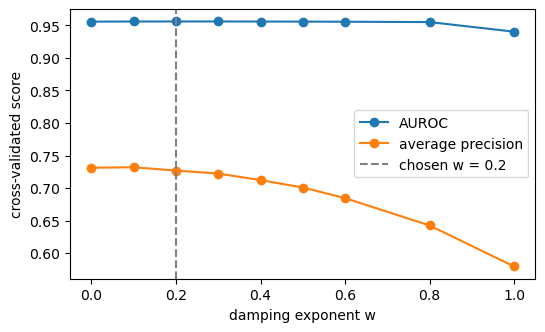

In [33]:
import matplotlib.pyplot as plt

figure, axis = plt.subplots(figsize=(6, 3.5))
axis.plot(w_results.index, w_results["AUROC"], marker="o", label="AUROC")
axis.plot(w_results.index, w_results["average precision"], marker="o", label="average precision")
axis.axvline(best_w, color="grey", linestyle="--", label=f"chosen w = {best_w}")
axis.set_xlabel("damping exponent w")
axis.set_ylabel("cross-validated score")
axis.legend()
plt.show()

**Reading the plot.** Compare how the two scores change with $w$. The AUROC changes very little over most of the range, so on HALD the exact value of $w$ matters less than in the sparser networks of the papers. Average precision, which looks at the very top of the ranking, is more sensitive. Because the AUROC differences are tiny, the "best" $w$ is not sharply determined; we follow the papers and take the value with the highest cross-validated AUROC, `best_w`. With only 132 positives, a difference in the third decimal place is within the noise.

One caveat: we chose $w$ with the same folds that we used to measure performance, so the scores in this table are slightly optimistic. We only use them to *compare* values of $w$, which is fair, because all values were treated alike.

### What we have so far
* `MeanArcsinh`, `make_ridge_model(C)`: the feature transformation and the classifier.
* `out_of_fold_scores(features, labels, C, random_seed)`: honest, cross-validated predictions.
* `dwpc_features(...)`: the DWPC feature table of our pairs for a list of metapaths and a value of $w$.
* `best_w`: the damping exponent we will use from now on.

**In Section 8** we compute the DWPC of **all** 516 metapaths at `best_w`, add the *degree* features of the gene and the disease, and look at which metapaths carry signal.

## Section 8: Model features

We now build the complete table of inputs for the model. Each row is one of our 20,132 pairs. There will be two kinds of columns: the **metapath features** (the DWPC of the pair for each metapath) and the **degree features** (how well connected the gene and the disease are).

### The metapath features
We compute the DWPC of **all 516 metapaths** at the damping exponent we chose, `best_w`. We also compute the plain **path count** ($w=0$) of every metapath, which will let us ask later whether the degree weighting actually helps. As in Section 7, we drop the metapaths that connect fewer than 5 of our pairs.

In [34]:
all_metapath_names = list(metapaths)
all_metapath_steps = [metapaths[name] for name in all_metapath_names]

dwpc_of_all_metapaths = dwpc_features(all_metapath_steps, best_w, adjacency_matrices, out_degree, in_degree,
                                      nodes_by_class, pair_rows, pair_columns)
path_counts_of_all_metapaths = dwpc_features(all_metapath_steps, 0.0, adjacency_matrices, out_degree, in_degree,
                                             nodes_by_class, pair_rows, pair_columns)

connects_enough_pairs = (path_counts_of_all_metapaths > 0).sum(axis=0) >= 5
metapath_names = [name for name, keep in zip(all_metapath_names, connects_enough_pairs) if keep]
metapath_features = dwpc_of_all_metapaths[:, connects_enough_pairs]          # DWPC at best_w
path_count_features = path_counts_of_all_metapaths[:, connects_enough_pairs]  # plain path count (w = 0)

print(f"{len(metapath_names)} of {len(all_metapath_names)} metapaths connect at least 5 pairs")
print("feature table shape (pairs x metapaths):", metapath_features.shape)

347 of 516 metapaths connect at least 5 pairs
feature table shape (pairs x metapaths): (20132, 347)


### The degree features
Project Rephetio also gave the model the **degrees** of the two nodes, in every metaedge they belong to:

$$d^{\text{out}}_{e}(s),\ d^{\text{in}}_{e}(s)\ \ (\text{for the gene } s),\qquad d^{\text{out}}_{e}(t),\ d^{\text{in}}_{e}(t)\ \ (\text{for the disease } t),$$

for every metaedge $e$ that starts or ends at Gene (for the gene) or at Disease (for the disease). These tell the model how "popular" the two nodes are, so the metapath features only have to explain what degree cannot. They also give us an important baseline: a model that sees *only* degrees cannot use any specific link between this gene and this disease.

We already have all the degrees (`out_degree` and `in_degree` from Section 3), so we only have to look them up. A feature that is the same for every pair is useless, so we drop any such column.

In [35]:
def degree_features(pairs, out_degree, in_degree):
    # For every metaedge touching Gene or Disease: the degree of each pair's gene / disease in it.
    columns, names = [], []
    for metaedge in out_degree:
        source_class, target_class = metaedge
        for role, position_in_pair in (("Gene", 0), ("Disease", 1)):
            nodes = [pair[position_in_pair] for pair in pairs]
            if source_class == role:
                columns.append([out_degree[metaedge][node] for node in nodes])
                names.append(f"{role}: out-degree in {source_class}>{target_class}")
            if target_class == role:
                columns.append([in_degree[metaedge][node] for node in nodes])
                names.append(f"{role}: in-degree in {source_class}>{target_class}")
    return np.array(columns, dtype=float).T, names

all_degree_features, all_degree_names = degree_features(all_pairs, out_degree, in_degree)
varies = all_degree_features.std(axis=0) > 0
degree_feature_table = all_degree_features[:, varies]
degree_names = [name for name, keep in zip(all_degree_names, varies) if keep]

print(len(degree_names), "degree features; table shape (pairs x features):", degree_feature_table.shape)
print("for example:", degree_names[:3])

37 degree features; table shape (pairs x features): (20132, 37)
for example: ['Disease: in-degree in Carbohydrate>Disease', 'Gene: in-degree in Carbohydrate>Gene', 'Disease: out-degree in Disease>Carbohydrate']


### How good is each metapath on its own?
Before combining everything, let us see how much signal each metapath carries by itself. We use the DWPC of one metapath directly as a score ("a larger DWPC means a more likely link"), and measure how well it separates the positives from the negatives with the **AUROC** and **average precision** (Section 7). No model is needed, because we only use that one column. The last columns show how many of the 132 positives the metapath connects at all, and its AUROC when we use the plain path count instead of the DWPC.

In [36]:
def single_feature_performance(features, feature_names, labels):
    # AUROC and average precision of each column used on its own as a score.
    rows = []
    for column, name in enumerate(feature_names):
        values = features[:, column]
        positives_connected = int((values[labels == 1] > 0).sum())
        rows.append((name, roc_auc_score(labels, values), average_precision_score(labels, values), positives_connected))
    return pd.DataFrame(rows, columns=["metapath", "AUROC", "average precision", "positives connected"]).set_index("metapath")

single_metapath_table = single_feature_performance(metapath_features, metapath_names, labels)
single_metapath_table["AUROC, plain path count"] = single_feature_performance(path_count_features, metapath_names, labels)["AUROC"]

single_metapath_table.sort_values("AUROC", ascending=False).head(12).round(3)

,AUROC,average precision,positives connected,"AUROC, plain path count"
metapath,,,,
Gene>Disease>Disease>Disease,0.954,0.705,125,0.940
Gene>Disease<Disease<Disease,0.951,0.707,124,0.940
Gene>Disease<Disease>Disease,0.942,0.706,122,0.940
Gene>Disease>Disease<Disease,0.938,0.704,122,0.939
Gene>Disease>Disease,0.930,0.672,115,0.930
Gene>Disease<Disease,0.929,0.672,115,0.930
Gene<Disease>Disease>Disease,0.927,0.662,116,0.923
Gene<Disease<Disease>Disease,0.927,0.656,116,0.923
Gene<Disease<Disease<Disease,0.927,0.655,116,0.922


**Reading the table.**

* **Chains through Disease–Disease edges lead the list.** Diseases are densely linked to each other, so such a chain connects almost every positive (112 to 125 of the 132 among the top twelve) and ranks them high. But a high score may only mean that the disease is a well-connected hub, not that this particular gene is related to it. **Section 9** tests this directly with permuted networks.
* **Degree weighting makes little difference here.** For most metapaths the AUROC with the DWPC is almost identical to the AUROC with the plain path count (last column): the median difference is 0.000, the weighting gains up to 0.03 for some metapaths and loses up to 0.02 for others.
* **Many metapaths are weak.** The metapaths with the lowest AUROC (close to 0.5) connect very few positives. A column that is non-zero for hardly any pair can only add noise.

### What we have so far
* `metapath_features` and `metapath_names`: the DWPC at `best_w` of every metapath that connects at least 5 pairs, and their names.
* `path_count_features`: the same metapaths with plain path counts, for comparison.
* `degree_feature_table` and `degree_names`: the degree features of the gene and the disease.
* `single_metapath_table`: the performance of each metapath on its own.

We have deliberately **not** yet trained a model on all these columns together. With hundreds of correlated features and only 132 positives, the regularisation strength $C$ must be chosen with care, and with the value we used in Section 7 the combined model does *worse* than a model of degree alone. We tune $C$ in Section 10.

**In Section 9** we build *permuted networks*, in which every node keeps its degrees but the specific connections are shuffled, and use them to find out which metapaths carry real signal beyond degree.

## Section 9: Permuted networks (null model)

### The question
Section 8 left us with a worry. Some metapaths score a high AUROC, but a node's degree alone can make a metapath look good: a route through well-connected nodes exists for almost any pair of well-connected nodes. Does a metapath tell us anything **beyond degree**?

### A null model that keeps the degrees
Both papers answer this with **permuted networks**. We shuffle the edges of every metaedge at random, but in a way that leaves every node's degrees untouched. A metapath can then only score well on the permuted network because of degree, since the specific connections are now random. If a metapath scores clearly better on the real network than on permuted ones, it carries real structure.

The shuffling is done by repeated **double edge swaps**. Pick two edges of the same metaedge, $a\to b$ and $c\to d$, and exchange their targets:

$$(a\to b),\ (c\to d)\ \longmapsto\ (a\to d),\ (c\to b).$$

Node $a$ still has one edge leaving it, $d$ still has one edge arriving, and so on, so all degrees are preserved. We skip a swap if it would create an edge that already exists or a self-loop. We attempt 10 swaps per edge, which rearranges most of the network.

### Comparing real and permuted
For each metapath $m$ we measure its AUROC on the real network, $\mathrm{AUC}_m$, and on each of $R$ permuted networks, $\mathrm{AUC}^{(1)}_m,\dots,\mathrm{AUC}^{(R)}_m$. We summarise the comparison in two ways:

$$z_m=\frac{\mathrm{AUC}_m-\overline{\mathrm{AUC}^{\text{perm}}_m}}{\operatorname{sd}\big(\mathrm{AUC}^{\text{perm}}_m\big)},\qquad
p_m=\frac{1+\#\{r:\ \mathrm{AUC}^{(r)}_m\ge \mathrm{AUC}_m\}}{1+R}.$$

The $z$ score says how many standard deviations the real AUROC is above the permuted ones. The empirical $p$ is the share of permuted networks that did at least as well, with a "+1" so that it is never 0. With $R=20$ permutations the smallest possible $p$ is $1/21\approx0.048$.

### Swapping the edges
The function below shuffles the edges of one metaedge. It draws all the random choices in advance, and everything it needs is passed in as an argument. (Node names are unique across classes, so `a == d` can only happen for a self-loop.)

In [37]:
def permute_edges(edges, random_generator, rounds_per_edge=10):
    # Shuffle the edges of one metaedge by double edge swaps; every node keeps its degree.
    edges = list(edges)
    existing_edges = set(edges)
    attempts = rounds_per_edge * len(edges)
    first_picks = random_generator.integers(len(edges), size=attempts)
    second_picks = random_generator.integers(len(edges), size=attempts)
    for i, j in zip(first_picks, second_picks):
        (a, b), (c, d) = edges[i], edges[j]
        if i == j or a == d or c == b or (a, d) in existing_edges or (c, b) in existing_edges:
            continue                                         # the swap would make a self-loop or a duplicate edge
        existing_edges -= {(a, b), (c, d)}
        existing_edges |= {(a, d), (c, b)}
        edges[i], edges[j] = (a, d), (c, b)
    return edges

### From shuffled edges to matrices
To compute DWPCs on a permuted network we need its adjacency matrices. The function below turns a dictionary of edge lists into sparse matrices, exactly as we did for the real network in Section 5, but as a reusable function. As a check, applying it to the real edges must reproduce the matrices we already have.

In [38]:
def build_adjacency_matrices(edges_by_metaedge, node_position, nodes_by_class):
    # One sparse 0/1 matrix per metaedge: rows = source nodes, columns = target nodes.
    matrices = {}
    for (source_class, target_class), edges in edges_by_metaedge.items():
        rows = [node_position[source_class][source] for source, target in edges]
        columns = [node_position[target_class][target] for source, target in edges]
        shape = (len(nodes_by_class[source_class]), len(nodes_by_class[target_class]))
        matrices[(source_class, target_class)] = sp.csr_matrix((np.ones(len(edges)), (rows, columns)), shape=shape)
    return matrices

rebuilt_matrices = build_adjacency_matrices(edges_by_metaedge, node_position, nodes_by_class)
assert all((rebuilt_matrices[metaedge] != adjacency_matrices[metaedge]).nnz == 0 for metaedge in adjacency_matrices)
print("check passed: the function reproduces the adjacency matrices of Section 5")

check passed: the function reproduces the adjacency matrices of Section 5


### Checking one permuted network
Before using the shuffled networks, we verify the two things that matter on one of them: every node has exactly the same degrees as before, and the connections really did change.

In [39]:
random_generator = np.random.default_rng(RANDOM_SEED)
example_permuted_edges = {metaedge: permute_edges(edges, random_generator) for metaedge, edges in edges_by_metaedge.items()}

for metaedge, edges in example_permuted_edges.items():
    assert Counter(source for source, target in edges) == out_degree[metaedge], "an out-degree changed"
    assert Counter(target for source, target in edges) == in_degree[metaedge], "an in-degree changed"

edges_before = sum(len(edges) for edges in edges_by_metaedge.values())
edges_changed = sum(len(set(example_permuted_edges[metaedge]) - set(edges)) for metaedge, edges in edges_by_metaedge.items())
print(f"check passed: all degrees are unchanged; {edges_changed:,} of {edges_before:,} edges now connect different nodes")

check passed: all degrees are unchanged; 49,367 of 59,638 edges now connect different nodes


### Running the permutations
For each of `NUMBER_OF_PERMUTATIONS` permuted networks we shuffle the edges, build the matrices, compute the DWPC of every kept metapath for our pairs at `best_w`, and record each metapath's AUROC. The degrees are unchanged, so the degree tables `out_degree` and `in_degree` from Section 3 are still valid and are reused. This takes about a minute.

We keep the feature table of the **first** permuted network only. In Section 10 we will train a model on it, to see how much of the model's performance comes from degree alone. (Keeping all of them would take a lot of memory.)

In [40]:
NUMBER_OF_PERMUTATIONS = 20
steps_of_kept_metapaths = [metapaths[name] for name in metapath_names]

random_generator = np.random.default_rng(RANDOM_SEED)
permuted_auroc_columns = []
for permutation_number in range(NUMBER_OF_PERMUTATIONS):
    permuted_edges = {metaedge: permute_edges(edges, random_generator) for metaedge, edges in edges_by_metaedge.items()}
    permuted_matrices = build_adjacency_matrices(permuted_edges, node_position, nodes_by_class)
    permuted_features = dwpc_features(steps_of_kept_metapaths, best_w, permuted_matrices, out_degree, in_degree,
                                      nodes_by_class, pair_rows, pair_columns)
    if permutation_number == 0:
        permuted_metapath_features = permuted_features              # kept for Section 10
    permuted_auroc_columns.append(single_feature_performance(permuted_features, metapath_names, labels)["AUROC"])

permuted_auroc = pd.concat(permuted_auroc_columns, axis=1)         # one row per metapath, one column per permutation
print(f"{NUMBER_OF_PERMUTATIONS} permuted networks done; AUROC table of shape", permuted_auroc.shape)

20 permuted networks done; AUROC table of shape (347, 20)


### The comparison table
For every metapath we put the real AUROC next to the permuted ones and compute the gain, $z$ and $p$ defined above. (A permuted AUROC that never varies would give a standard deviation of 0, so we turn such a $z$ into "not a number" rather than dividing by zero.)

In [41]:
null_comparison = pd.DataFrame({
    "AUROC real": single_metapath_table["AUROC"],
    "AUROC permuted (mean)": permuted_auroc.mean(axis=1),
    "AUROC permuted (sd)": permuted_auroc.std(axis=1),
})
null_comparison["gain over permuted"] = null_comparison["AUROC real"] - null_comparison["AUROC permuted (mean)"]
null_comparison["z"] = null_comparison["gain over permuted"] / null_comparison["AUROC permuted (sd)"].replace(0, np.nan)

at_least_as_good = [(permuted_auroc.loc[name] >= null_comparison.loc[name, "AUROC real"]).sum() for name in null_comparison.index]
null_comparison["empirical p"] = (1 + np.array(at_least_as_good)) / (1 + NUMBER_OF_PERMUTATIONS)

print("The metapaths with the highest AUROC on the real network:")
null_comparison.sort_values("AUROC real", ascending=False).head(8).round(3)

The metapaths with the highest AUROC on the real network:


,AUROC real,AUROC permuted (mean),AUROC permuted (sd),gain over permuted,z,empirical p
metapath,,,,,,
Gene>Disease>Disease>Disease,0.954,0.965,0.004,-0.011,-2.887,0.952
Gene>Disease<Disease<Disease,0.951,0.965,0.003,-0.014,-5.391,1.000
Gene>Disease<Disease>Disease,0.942,0.964,0.004,-0.022,-5.133,1.000
Gene>Disease>Disease<Disease,0.938,0.964,0.004,-0.026,-6.113,1.000
Gene>Disease>Disease,0.930,0.926,0.008,0.003,0.431,0.381
Gene>Disease<Disease,0.929,0.926,0.009,0.003,0.364,0.381
Gene<Disease>Disease>Disease,0.927,0.921,0.007,0.006,0.864,0.048
Gene<Disease<Disease>Disease,0.927,0.922,0.005,0.005,0.976,0.048


Now rank the metapaths by what really matters, the **gain over the permuted networks**.

In [42]:
print("The metapaths that beat the permuted networks by the most:")
null_comparison.sort_values("gain over permuted", ascending=False).head(10).round(3)

The metapaths that beat the permuted networks by the most:


,AUROC real,AUROC permuted (mean),AUROC permuted (sd),gain over permuted,z,empirical p
metapath,,,,,,
Gene>Disease,0.795,0.631,0.012,0.164,14.151,0.048
Gene<Disease,0.712,0.601,0.014,0.111,8.153,0.048
Gene<Gene<Mutation>Disease,0.576,0.523,0.008,0.052,6.992,0.048
Gene<Gene<Disease,0.757,0.705,0.019,0.052,2.809,0.048
Gene>Gene>Lipid<Disease,0.760,0.712,0.019,0.048,2.479,0.048
Gene<Gene<Carbohydrate<Disease,0.756,0.710,0.021,0.047,2.220,0.048
Gene<Gene>Lipid<Disease,0.752,0.707,0.017,0.046,2.697,0.048
Gene>Gene<Disease,0.757,0.711,0.017,0.046,2.628,0.048
Gene>Carbohydrate<Disease,0.647,0.605,0.019,0.043,2.222,0.048


### Reading the results

* **The best raw scores are mostly degree.** The four longest Disease–Disease chains at the top of the first table have a permuted AUROC that is *higher than* the real one (for example `Gene>Disease>Disease>Disease`: 0.954 real against 0.965 permuted). A shuffled network that only keeps the degrees does just as well, so these metapaths measure how well connected a disease is, not whether this gene is related to it.
* **The direct links carry real structure.** `Gene>Disease` has AUROC 0.795 on the real network and only 0.631 on permuted ones, about 14 standard deviations apart ($z\approx14$), and `Gene<Disease` is similar (0.712 against 0.601, $z\approx8$). The specific gene–disease connections, not the degrees, are doing the work here.
* **Many metapaths are worse than the null.** The gain is negative for 103 of the 347 metapaths.
* **How many metapaths are "significant"?** 70 of the 347 reach the smallest possible $p$ ($\approx0.048$ with 20 permutations). With so many metapaths tested, a few would reach that by chance alone (about 5% of them, around 17), so a small $p$ is a hint and not a proof.

### What we have so far
* `permute_edges(...)` and `build_adjacency_matrices(...)`: degree-preserving shuffling and its matrices.
* `null_comparison`: for every metapath, the real AUROC, the permuted AUROC, the gain, $z$ and an empirical $p$.
* `permuted_metapath_features`: the features of one permuted network, for Section 10.

**In Section 10** we train the ridge logistic regression on all the features together, tune its regularisation strength $C$, and compare models: degree only, metapaths only, both, plain path counts, and the permuted network.

## Section 10: Logistic regression and cross-validation

### Putting everything into one model
Now we use all the features together: the DWPC of the 347 metapaths and the 37 degree features. The classifier is the ridge logistic regression of Section 7, scored with the same 5-fold out-of-fold predictions. One thing is left to decide: the regularisation strength $C$.

### Choosing the regularisation strength $C$
In Section 7 we fixed $C=0.01$, which was fine for 24 features. With 384 correlated features and only 132 positives the model needs a much **stronger** penalty (a smaller $C$), otherwise it over-fits. (At $C=0.01$ the combined model scores clearly worse than a model of degree alone, which was the reason we postponed the model comparison to this section.)

We try a range of values and keep the one with the best cross-validated AUROC. The function below returns the AUROC and average precision of one feature table.

In [43]:
def evaluate_feature_set(features, labels, C, random_seed):
    # Out-of-fold AUROC and average precision of the ridge model on one table of features.
    scores = out_of_fold_scores(features, labels, C, random_seed)
    return roc_auc_score(labels, scores), average_precision_score(labels, scores)

metapath_and_degree_features = np.hstack([metapath_features, degree_feature_table])

c_results = []
for C in [0.00001, 0.00003, 0.0001, 0.0003, 0.001, 0.003, 0.01]:
    auroc, average_precision = evaluate_feature_set(metapath_and_degree_features, labels, C, RANDOM_SEED)
    c_results.append((C, auroc, average_precision))

c_results = pd.DataFrame(c_results, columns=["C", "AUROC", "average precision"]).set_index("C")
best_C = c_results["AUROC"].idxmax()
print("chosen regularisation strength: C =", best_C)
c_results.round(4)

chosen regularisation strength: C = 3e-05


,AUROC,average precision
C,,
0.00001,0.9873,0.7451
0.00003,0.9875,0.7618
0.00010,0.9875,0.7803
0.00030,0.9867,0.7789
0.00100,0.9819,0.7544
0.00300,0.9669,0.7226
0.01000,0.9403,0.6799


**Reading the table.** Performance is flat for the smallest values of $C$ and then drops quickly as $C$ grows, so strong regularisation is needed. The AUROC of the smallest few values differs only in the fourth decimal place, and average precision is highest at $C=0.0001$; the choice among them is not sharp, and any of them would give essentially the same conclusions. As with $w$, the folds used to choose $C$ are the folds we score on, so the numbers for the combined model are slightly optimistic. We use the **same** $C$ for every feature set below, so the comparison between them is fair.

### Comparing feature sets
We now score seven feature sets with the same model and the same folds. Each answers a question:

| Feature set | Question it answers |
|---|---|
| degree features only | how much can degree alone explain? |
| DWPC | how much do the metapaths alone explain? |
| DWPC + degree | the full model of Project Rephetio |
| path count ($w=0$), with and without degree | does degree weighting help? |
| DWPC on a **permuted** network, with and without degree | what do we get from degree alone, passed through the DWPC machinery, with the real connections destroyed? |

In [44]:
feature_sets = {
    "degree features only": degree_feature_table,
    f"DWPC (w={best_w})": metapath_features,
    f"DWPC (w={best_w}) + degree": metapath_and_degree_features,
    "path count (w=0)": path_count_features,
    "path count (w=0) + degree": np.hstack([path_count_features, degree_feature_table]),
    "DWPC, permuted network": permuted_metapath_features,
    "DWPC, permuted network + degree": np.hstack([permuted_metapath_features, degree_feature_table]),
}

comparison_rows = []
for name, features in feature_sets.items():
    auroc, average_precision = evaluate_feature_set(features, labels, best_C, RANDOM_SEED)
    comparison_rows.append((name, auroc, average_precision))

model_comparison = pd.DataFrame(comparison_rows, columns=["features", "AUROC", "average precision"]).set_index("features")
model_comparison.round(3)

,AUROC,average precision
features,,
degree features only,0.982,0.652
DWPC (w=0.2),0.979,0.743
DWPC (w=0.2) + degree,0.987,0.762
path count (w=0),0.979,0.728
path count (w=0) + degree,0.987,0.750
"DWPC, permuted network",0.974,0.698
"DWPC, permuted network + degree",0.985,0.716


### Reading the comparison

* **Degree alone is already very strong (AUROC 0.982).** Our negatives are random pairs, and the positives are well-connected genes and diseases (Section 6), so telling them apart is easy. This is why the AUROC differences below are small.
* **The metapaths add precision, not much AUROC.** DWPC + degree reaches an AUROC of 0.987, but its average precision is 0.762 against 0.652 for degree alone: the metapaths help most at the top of the ranking, where it matters for finding new candidates.
* **Degree weighting helps only slightly.** DWPC + degree beats path count + degree by a hair in average precision (0.762 against 0.750), and the AUROC is the same, matching what we saw for single metapaths in Section 8.
* **The permuted network gives a baseline for "degree in disguise".** Features computed on a shuffled network, which keeps all degrees but no real connections, plus degree give average precision 0.716: better than degree alone, because the DWPC encodes degree information in a convenient form. The real network does better again (0.762), a small gain that we can attribute to real structure. This rests on a single permuted network, so we should not read much into a difference of 0.05.

### Which features does the model rely on?
Because every feature has been turned into a z-score, the coefficients $\hat\beta_j$ of the fitted model are directly comparable: each is the change in the log-odds of a link per standard deviation of the feature. We fit the model on all the data once, only to read the coefficients; the scores above all came from held-out folds.

In [45]:
final_model = make_ridge_model(best_C).fit(metapath_and_degree_features, labels)
coefficients = pd.Series(final_model[-1].coef_[0], index=metapath_names + degree_names).sort_values(ascending=False)

print("largest positive coefficients:")
print(coefficients.head(10).round(3).to_string())
print("\nlargest negative coefficients:")
print(coefficients.tail(5).round(3).to_string())

largest positive coefficients:
Gene>Disease                                  0.076
Disease: in-degree in Gene>Disease            0.046
Disease: out-degree in Disease>Protein        0.040
Disease: out-degree in Disease>Gene           0.038
Gene<Disease>Disease                          0.037
Disease: in-degree in Protein>Disease         0.036
Gene>Disease>Disease                          0.036
Disease: in-degree in Carbohydrate>Disease    0.035
Disease: in-degree in Peptide>Disease         0.034
Disease: out-degree in Disease>Disease        0.033

largest negative coefficients:
Gene>Carbohydrate<Disease>Disease   -0.005
Gene>Carbohydrate>Disease<Disease   -0.005
Gene>Carbohydrate<Disease<Disease   -0.005
Gene>Carbohydrate>Disease>Disease   -0.005
Gene: in-degree in Mutation>Gene    -0.006


**Reading the coefficients.** The direct link `Gene>Disease` has the largest coefficient, in line with its strong result against the permuted networks in Section 9. Several degree features of the disease follow, and so do a few metapaths. Coefficients of correlated features share the credit between them (the ridge penalty spreads weight over similar features), so read them as a rough guide, not as a ranking of causes.

### What we have so far
* `best_C` and `c_results`: the chosen regularisation strength.
* `model_comparison`: seven feature sets scored with the same model and folds.
* `final_model` and `coefficients`: the model fitted on all the data, and its standardised coefficients.

**In Section 11**, the last section, we will look at the predictions themselves: the ROC curves of the main models and what they mean in practice, and the main caveats of the whole analysis.

## Section 11: ROC analysis and interpretation

### What an ROC curve shows
A model gives every pair a **score**. To turn scores into decisions we pick a **threshold**: pairs scoring at least the threshold are predicted positive. For any threshold two rates matter:

$$\mathrm{TPR}=\frac{\text{true positives}}{\text{all positives}}\quad(\text{the share of real links we find}),\qquad
\mathrm{FPR}=\frac{\text{false positives}}{\text{all negatives}}\quad(\text{the share of non-links we wrongly flag}).$$

Lowering the threshold finds more real links (TPR rises) but also flags more non-links (FPR rises). The **ROC curve** plots TPR against FPR as the threshold sweeps from the highest score to the lowest. A model that guesses follows the diagonal; a good model rises steeply at the left, and the **area under the curve** (the AUROC we have been using) summarises it in one number.

We draw the curves from the **out-of-fold scores** of Section 7, so every pair was scored by a model that never saw it. We compare the three models that tell the main story: degree only, DWPC only, and both. The left plot shows the whole curve, and the right plot zooms in on the left edge (FPR below 5%), which is the part that matters when only the top of the ranking will be examined.

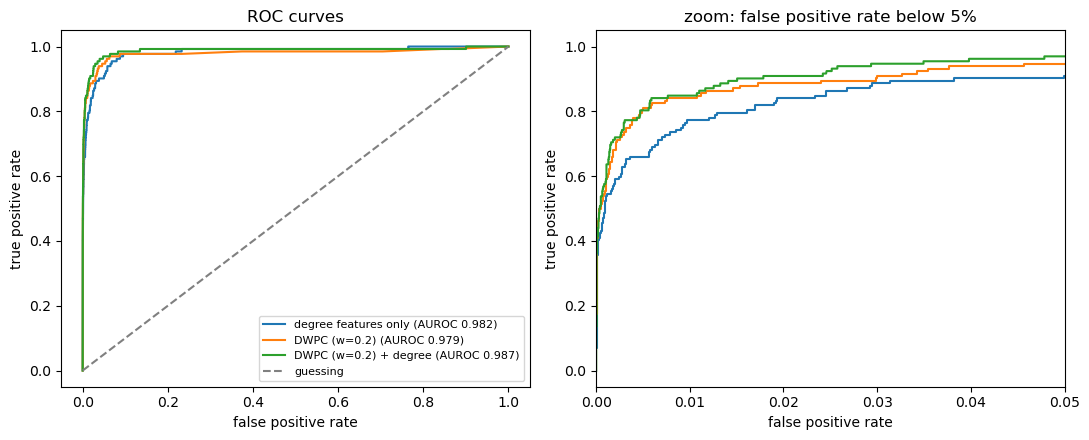

In [46]:
from sklearn.metrics import roc_curve

models_to_compare = {
    "degree features only": degree_feature_table,
    f"DWPC (w={best_w})": metapath_features,
    f"DWPC (w={best_w}) + degree": metapath_and_degree_features,
}
out_of_fold = {name: out_of_fold_scores(features, labels, best_C, RANDOM_SEED) for name, features in models_to_compare.items()}

figure, (whole_curve, left_edge) = plt.subplots(1, 2, figsize=(11, 4.5))
for name, scores in out_of_fold.items():
    false_positive_rate, true_positive_rate, thresholds = roc_curve(labels, scores)
    label = f"{name} (AUROC {roc_auc_score(labels, scores):.3f})"
    whole_curve.plot(false_positive_rate, true_positive_rate, label=label)
    left_edge.plot(false_positive_rate, true_positive_rate)
whole_curve.plot([0, 1], [0, 1], color="grey", linestyle="--", label="guessing")
whole_curve.set_title("ROC curves"); whole_curve.legend(loc="lower right", fontsize=8)
left_edge.set_xlim(0, 0.05); left_edge.set_title("zoom: false positive rate below 5%")
for axis in (whole_curve, left_edge):
    axis.set_xlabel("false positive rate"); axis.set_ylabel("true positive rate")
plt.tight_layout()
plt.show()

### What the curves mean in practice
Curves that all hug the top-left corner are hard to tell apart by eye, so we read numbers off them. The function below picks the threshold that allows at most a given false positive rate, and reports the share of positives found (TPR) and the **precision** at that threshold: of the pairs we flag, the share that really are positives.

In [47]:
def rates_at_false_positive_rate(labels, scores, max_false_positive_rate):
    # TPR and precision at the lowest threshold whose false positive rate stays within the limit.
    false_positive_rate, true_positive_rate, thresholds = roc_curve(labels, scores)
    last_allowed = np.where(false_positive_rate <= max_false_positive_rate)[0][-1]
    true_positives = true_positive_rate[last_allowed] * (labels == 1).sum()
    false_positives = false_positive_rate[last_allowed] * (labels == 0).sum()
    return true_positive_rate[last_allowed], true_positives / (true_positives + false_positives)

rows = []
for name, scores in out_of_fold.items():
    for limit in [0.001, 0.01, 0.05]:
        true_positive_rate, precision = rates_at_false_positive_rate(labels, scores, limit)
        rows.append((name, f"{limit:.1%}", true_positive_rate, precision))

pd.DataFrame(rows, columns=["model", "false positive rate allowed", "share of positives found", "precision"]).round(3)

,model,false positive rate allowed,share of positives found,precision
0,degree features only,0.1%,0.530,0.778
1,degree features only,1.0%,0.773,0.345
2,degree features only,5.0%,0.909,0.107
3,DWPC (w=0.2),0.1%,0.583,0.794
4,DWPC (w=0.2),1.0%,0.841,0.424
5,DWPC (w=0.2),5.0%,0.947,0.120
6,DWPC (w=0.2) + degree,0.1%,0.583,0.794
7,DWPC (w=0.2) + degree,1.0%,0.848,0.423
8,DWPC (w=0.2) + degree,5.0%,0.970,0.114


**Reading the table.** Allowing 1% false positives, the DWPC models find about 84% of the known positives, against 77% for degree alone, with a precision of about 42%. At the strictest limit (0.1%) the gap is similar, and at 5% the combined model finds 97%. The metapaths help most at the top of the ranking, as the zoomed plot suggests.

### A warning about precision
Precision depends on how many negatives there are. Our data set has 20,000 negatives, only a sample of the 19.7 million possible gene–disease pairs. A false positive rate of 1% on all 19.7 million pairs would be nearly 200,000 false alarms, against at most a few hundred real links, so the precision in a real search of every pair would be **far lower** than in the table. To search the whole space one needs a false positive rate of the order of one in a hundred thousand, and the performance at that level has to be judged from the extreme left edge of the curve, where we have almost no data. The AUROC and the precision above compare models against each other, but they do not predict how many of the top candidates in a real search would be true.

### The best-scoring pairs
Finally, what does the model rank highest among our **negative** examples? These are pairs HALD does not list as `reduce`, which the model, scoring them out-of-fold, finds most similar to the known positives.

In [48]:
final_scores = out_of_fold[f"DWPC (w={best_w}) + degree"]
ranking = np.argsort(-final_scores)
print("known positives among the 100 highest-scoring pairs:", labels[ranking[:100]].sum(), "| among the 300 highest:", labels[ranking[:300]].sum())

negative_positions = np.where(labels == 0)[0]
top_negatives = negative_positions[np.argsort(-final_scores[negative_positions])[:10]]
pd.DataFrame({"gene": [all_pairs[i][0] for i in top_negatives],
              "disease": [all_pairs[i][1] for i in top_negatives],
              "model score": final_scores[top_negatives].round(3)})

known positives among the 100 highest-scoring pairs: 78 | among the 300 highest: 112


,gene,disease,model score
0,SIRT1,Heart_Diseases,1.000
1,FOXO3,Renal_Insufficiency_Chronic,1.000
2,FTO,Neoplasms,0.999
3,TAT,Dementia,0.999
4,PTH,Heart_Diseases,0.999
5,INS,Fatigue,0.998
6,APOE,Muscle_Weakness,0.997
7,BDNF,Arthritis_Rheumatoid,0.997
8,SYP,Neurodegenerative_Diseases,0.996
9,CLOCK,Parkinson_Disease,0.996


**Reading the list.** Many of these look biologically plausible (for example genes such as `SIRT1`, `FOXO3` and `INS` with ageing-related diseases). They may be real relationships that HALD does not record as `reduce`, which is exactly the kind of candidate a link-prediction method is meant to surface, and also a reminder that some of our "negatives" are not truly negative. We have **not** checked any of them: a high score is a lead to investigate in the literature, not a finding. The scores are also not probabilities: because we weighted the two classes to balance them, the model gives high scores far too freely, and only the *ranking* of the pairs is meaningful.

### Summary of the analysis
1. We turned HALD into a typed network, with the target relation `Gene –reduce→ Disease` hidden from it (Sections 1 to 3).
2. We described routes between a gene and a disease as metapaths, and counted them with the degree-weighted path count, which discounts routes through hub nodes, verified against an independent route-by-route count (Sections 4 and 5).
3. We built a data set of 132 positives and 20,000 random negatives and chose the damping exponent $w=0.2$ by cross-validation (Sections 6 and 7).
4. We compared the metapath features with the degree features and with permuted networks that keep the degrees (Sections 8 and 9). **Direct gene–disease links carry real structure; the long Disease–Disease chains mostly measure how well connected a disease is.**
5. A ridge logistic regression reaches an AUROC of 0.987. Degree alone already gives 0.982, so the main benefit of the metapaths is **precision at the top of the ranking** (average precision 0.76 against 0.65) (Section 10).

### Caveats and ideas for going further
* **Only 132 positives**, so every performance number is noisy, and differences in the third decimal place mean nothing.
* **Easy negatives.** Random pairs reward hub nodes, which is why degree alone does so well. A fairer test uses **degree-matched negatives**: for each positive, negatives whose gene and disease have similar degrees. Then a model has to use the specific links.
* **Predicates collapsed.** We ignored what the edges say (`associated`, `treated`, `reduce`, ...). Grouping predicates by meaning would give more specific metapaths.
* **Choices tuned on the scoring folds.** We chose $w$ and $C$ with the same folds we scored on, so the combined-model numbers are slightly optimistic. A final untouched test set would remove this.
* **One permuted network** was used for the model comparison, and metapath significance among 347 tests needs care (Section 9).
* **Metapath length.** We stopped at length 3. Longer metapaths need the route-by-route counter of Section 5, which is much slower.
* **Text-mined data.** HALD comes from the literature, so its edges can be wrong or incomplete, and a predicted link says only that the graph's structure supports it.

**References.** Himmelstein DS & Baranzini SE (2015) *Heterogeneous network edge prediction: a data integration approach to prioritize disease-associated genes.* PLoS Comput Biol 11(7):e1004259.
Himmelstein DS et al. (2017) *Systematic integration of biomedical knowledge prioritizes drugs for repurposing.* eLife 6:e26726.